In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving AlertaStock_dataset_V2_52_semanas.csv to AlertaStock_dataset_V2_52_semanas.csv


In [ ]:
import os
os.listdir()

['.config', 'AlertaStock_dataset_V2_52_semanas.csv', 'sample_data']

In [ ]:
df = pd.read_csv("AlertaStock_dataset_V2_52_semanas.csv")

df.head()

,productoId,semana,cantidad_vendida,ingresos,nombre,categoria,precioVenta,precioCompra,stockActual,stockMinimo,...,promocion,descuento_pct,festivo_cercano,quincena,mes,semana_del_ano,fechaVencimiento,dias_para_vencimiento,esta_venciendo_30d,perecedero
0,1,2025-08-25,10,65000,Gaseosa 1.5L,Bebidas,6500,4100,14,8,...,False,0,False,True,8,35,NaN,NaN,False,False
1,2,2025-08-25,15,36000,Agua 600ml,Bebidas,2400,1300,22,8,...,True,5,False,True,8,35,NaN,NaN,False,False
2,3,2025-08-25,12,86400,Jugo naranja 1L,Bebidas,7200,4700,17,7,...,False,0,False,True,8,35,2025-10-06,42.0,False,True
3,4,2025-08-25,10,42000,Cerveza 330ml,Bebidas,4200,2700,8,8,...,False,0,False,True,8,35,NaN,NaN,False,False
4,5,2025-08-25,12,70800,Malta 400ml,Bebidas,5900,4400,14,8,...,False,0,False,True,8,35,NaN,NaN,False,False


In [ ]:
# ============================================
# 1. CARACTERIZACIÓN INICIAL DEL DATASET
# ============================================

# Convertimos la fecha de semana a formato datetime
df["semana"] = pd.to_datetime(df["semana"])

print("Dimensiones del dataset:")
print(df.shape)

print("\nNúmero de productos:")
print(df["productoId"].nunique())

print("\nNúmero de categorías:")
print(df["categoria"].nunique())

print("\nPeriodo analizado:")
print("Desde:", df["semana"].min().date())
print("Hasta:", df["semana"].max().date())

print("\nNúmero de semanas:")
print(df["semana"].nunique())

print("\nValores nulos por columna:")
print(df.isnull().sum())

print("\nTipos de datos:")
print(df.dtypes)

Dimensiones del dataset:
(1872, 27)

Número de productos:
36

Número de categorías:
7

Periodo analizado:
Desde: 2025-08-25
Hasta: 2026-08-17

Número de semanas:
52

Valores nulos por columna:
productoId                  0
semana                      0
cantidad_vendida            0
ingresos                    0
nombre                      0
categoria                   0
precioVenta                 0
precioCompra                0
stockActual                 0
stockMinimo                 0
lag_1                       0
lag_2                       0
lag_3                       0
lag_4                       0
promedio_movil_4            0
promedio_movil_8            0
tendencia_4                 0
promocion                   0
descuento_pct               0
festivo_cercano             0
quincena                    0
mes                         0
semana_del_ano              0
fechaVencimiento         1300
dias_para_vencimiento    1300
esta_venciendo_30d          0
perecedero                 

In [ ]:
# ============================================
# 2. REVISIÓN DE RELACIONES ENTRE VARIABLES
# ============================================

columnas_numericas = [
    "cantidad_vendida",
    "precioVenta",
    "precioCompra",
    "stockActual",
    "stockMinimo",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_4",
    "promedio_movil_4",
    "promedio_movil_8",
    "tendencia_4",
    "descuento_pct",
    "mes",
    "semana_del_ano"
]

correlaciones = (
    df[columnas_numericas]
    .corr(numeric_only=True)["cantidad_vendida"]
    .sort_values(ascending=False)
)

print("Correlación con cantidad_vendida:\n")
print(correlaciones)

Correlación con cantidad_vendida:

cantidad_vendida    1.000000
promedio_movil_4    0.887315
promedio_movil_8    0.884477
lag_1               0.878054
lag_2               0.854362
stockActual         0.845676
stockMinimo         0.818122
lag_3               0.816342
lag_4               0.811951
descuento_pct       0.267641
tendencia_4         0.121927
mes                 0.120674
semana_del_ano      0.118270
precioCompra       -0.442150
precioVenta        -0.457604
Name: cantidad_vendida, dtype: float64


In [ ]:
# ============================================
# 3. SELECCIÓN DE CARACTERÍSTICAS
# ============================================

# Variable que queremos predecir
variable_objetivo = "cantidad_vendida"

# Variables numéricas utilizadas por el modelo
variables_numericas = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_4",
    "promedio_movil_4",
    "promedio_movil_8",
    "tendencia_4",
    "descuento_pct",
    "mes",
    "semana_del_ano"
]

# Variable categórica
variables_categoricas = [
    "categoria"
]

caracteristicas = variables_numericas + variables_categoricas

print("Variable objetivo:")
print(variable_objetivo)

print("\nCaracterísticas utilizadas:")
for variable in caracteristicas:
    print("-", variable)

print("\nNúmero de características originales:")
print(len(caracteristicas))

Variable objetivo:
cantidad_vendida

Características utilizadas:
- lag_1
- lag_2
- lag_3
- lag_4
- promedio_movil_4
- promedio_movil_8
- tendencia_4
- descuento_pct
- mes
- semana_del_ano
- categoria

Número de características originales:
11


In [ ]:
# ============================================
# 4. PREPROCESAMIENTO DE LAS VARIABLES
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Las variables categóricas se convierten a formato numérico
# mediante OneHotEncoder.
#
# Las variables numéricas pasan sin escalamiento ("passthrough")
# porque los modelos principales evaluados no requieren
# obligatoriamente normalización para realizar la predicción.

preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            "passthrough",
            variables_numericas
        )
    ]
)

print("Preprocesador creado correctamente.")
print("\nVariables categóricas:")
print(variables_categoricas)

print("\nVariables numéricas:")
print(variables_numericas)

Preprocesador creado correctamente.

Variables categóricas:
['categoria']

Variables numéricas:
['lag_1', 'lag_2', 'lag_3', 'lag_4', 'promedio_movil_4', 'promedio_movil_8', 'tendencia_4', 'descuento_pct', 'mes', 'semana_del_ano']


In [ ]:
# ============================================
# 5. VERIFICAR LAS VARIABLES TRANSFORMADAS
# ============================================

X_temporal = df[caracteristicas]

# Ajustamos solamente para inspeccionar
# cómo quedarán las variables después del preprocesamiento
preprocesador.fit(X_temporal)

nombres_transformados = preprocesador.get_feature_names_out()

print("Número de características originales:")
print(len(caracteristicas))

print("\nNúmero de características después del preprocesamiento:")
print(len(nombres_transformados))

print("\nCaracterísticas transformadas:")
for nombre in nombres_transformados:
    print("-", nombre)

Número de características originales:
11

Número de características después del preprocesamiento:
17

Características transformadas:
- categoricas__categoria_Aseo
- categoricas__categoria_Bebidas
- categoricas__categoria_Cuidado personal
- categoricas__categoria_Enlatados
- categoricas__categoria_Lácteos
- categoricas__categoria_Panadería
- categoricas__categoria_Snacks
- numericas__lag_1
- numericas__lag_2
- numericas__lag_3
- numericas__lag_4
- numericas__promedio_movil_4
- numericas__promedio_movil_8
- numericas__tendencia_4
- numericas__descuento_pct
- numericas__mes
- numericas__semana_del_ano


In [ ]:
# ============================================
# 6. DIVISIÓN TEMPORAL:
# ENTRENAMIENTO / VALIDACIÓN / PRUEBA
# ============================================

# Ordenamos cronológicamente
df = df.sort_values(
    by=["semana", "productoId"]
).reset_index(drop=True)

# Semanas únicas ordenadas
semanas = sorted(df["semana"].unique())

print("Total de semanas:", len(semanas))

# 36 semanas entrenamiento
semanas_train = semanas[:36]

# 8 semanas validación
semanas_val = semanas[36:44]

# 8 semanas prueba final
semanas_test = semanas[44:52]

train = df[df["semana"].isin(semanas_train)].copy()
val = df[df["semana"].isin(semanas_val)].copy()
test = df[df["semana"].isin(semanas_test)].copy()

print("\nENTRENAMIENTO")
print("Registros:", len(train))
print("Desde:", train["semana"].min().date())
print("Hasta:", train["semana"].max().date())

print("\nVALIDACIÓN")
print("Registros:", len(val))
print("Desde:", val["semana"].min().date())
print("Hasta:", val["semana"].max().date())

print("\nPRUEBA FINAL")
print("Registros:", len(test))
print("Desde:", test["semana"].min().date())
print("Hasta:", test["semana"].max().date())

Total de semanas: 52

ENTRENAMIENTO
Registros: 1296
Desde: 2025-08-25
Hasta: 2026-04-27

VALIDACIÓN
Registros: 288
Desde: 2026-05-04
Hasta: 2026-06-22

PRUEBA FINAL
Registros: 288
Desde: 2026-06-29
Hasta: 2026-08-17


In [ ]:
# ============================================
# 7. DEFINICIÓN DE X / y Y BASELINE
# ============================================

X_train = train[caracteristicas]
y_train = train[variable_objetivo]

X_val = val[caracteristicas]
y_val = val[variable_objetivo]

X_test = test[caracteristicas]
y_test = test[variable_objetivo]

print("Dimensiones:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

Dimensiones:
X_train: (1296, 11)
X_val: (288, 11)
X_test: (288, 11)


In [ ]:
# ============================================
# 8. BASELINE: USAR lag_1 COMO PREDICCIÓN
# ============================================

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

pred_baseline_val = val["lag_1"]

mae_baseline_val = mean_absolute_error(
    y_val,
    pred_baseline_val
)

rmse_baseline_val = root_mean_squared_error(
    y_val,
    pred_baseline_val
)

r2_baseline_val = r2_score(
    y_val,
    pred_baseline_val
)

print("BASELINE - VALIDACIÓN")
print("MAE:", round(mae_baseline_val, 3))
print("RMSE:", round(rmse_baseline_val, 3))
print("R²:", round(r2_baseline_val, 3))

BASELINE - VALIDACIÓN
MAE: 1.181
RMSE: 1.665
R²: 0.698


In [ ]:
# ============================================
# 9. REGRESIÓN LINEAL
# ============================================

from sklearn.linear_model import LinearRegression

pipeline_lineal = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", LinearRegression())
    ]
)

# Entrenamiento SOLO con train
pipeline_lineal.fit(X_train, y_train)

# Predicción sobre validación
pred_lineal_val = pipeline_lineal.predict(X_val)

# Métricas
mae_lineal_val = mean_absolute_error(
    y_val,
    pred_lineal_val
)

rmse_lineal_val = root_mean_squared_error(
    y_val,
    pred_lineal_val
)

r2_lineal_val = r2_score(
    y_val,
    pred_lineal_val
)

print("REGRESIÓN LINEAL - VALIDACIÓN")
print("MAE:", round(mae_lineal_val, 3))
print("RMSE:", round(rmse_lineal_val, 3))
print("R²:", round(r2_lineal_val, 3))

REGRESIÓN LINEAL - VALIDACIÓN
MAE: 0.945
RMSE: 1.204
R²: 0.842


In [ ]:
# ============================================
# 10. RANDOM FOREST - MODELO INICIAL
# ============================================

from sklearn.ensemble import RandomForestRegressor

pipeline_rf_inicial = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "modelo",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=5,
                random_state=42
            )
        )
    ]
)

# Entrenamiento
pipeline_rf_inicial.fit(X_train, y_train)

# Predicciones
pred_rf_train = pipeline_rf_inicial.predict(X_train)
pred_rf_val = pipeline_rf_inicial.predict(X_val)

# Métricas entrenamiento
mae_rf_train = mean_absolute_error(
    y_train,
    pred_rf_train
)

rmse_rf_train = root_mean_squared_error(
    y_train,
    pred_rf_train
)

r2_rf_train = r2_score(
    y_train,
    pred_rf_train
)

# Métricas validación
mae_rf_val = mean_absolute_error(
    y_val,
    pred_rf_val
)

rmse_rf_val = root_mean_squared_error(
    y_val,
    pred_rf_val
)

r2_rf_val = r2_score(
    y_val,
    pred_rf_val
)

print("RANDOM FOREST INICIAL")

print("\nENTRENAMIENTO")
print("MAE:", round(mae_rf_train, 3))
print("RMSE:", round(rmse_rf_train, 3))
print("R²:", round(r2_rf_train, 3))

print("\nVALIDACIÓN")
print("MAE:", round(mae_rf_val, 3))
print("RMSE:", round(rmse_rf_val, 3))
print("R²:", round(r2_rf_val, 3))

RANDOM FOREST INICIAL

ENTRENAMIENTO
MAE: 0.906
RMSE: 1.149
R²: 0.899

VALIDACIÓN
MAE: 0.948
RMSE: 1.264
R²: 0.826


In [ ]:
# ============================================
# 11. AJUSTE DE max_depth EN RANDOM FOREST
# ============================================

resultados_profundidad = []

profundidades = [3, 5, 7, 10, None]

for profundidad in profundidades:

    modelo_rf = Pipeline(
        steps=[
            ("preprocesamiento", preprocesador),
            (
                "modelo",
                RandomForestRegressor(
                    n_estimators=100,
                    max_depth=profundidad,
                    random_state=42
                )
            )
        ]
    )

    modelo_rf.fit(X_train, y_train)

    pred_train = modelo_rf.predict(X_train)
    pred_val = modelo_rf.predict(X_val)

    resultados_profundidad.append({
        "max_depth": str(profundidad),

        "MAE_train":
            mean_absolute_error(y_train, pred_train),

        "MAE_val":
            mean_absolute_error(y_val, pred_val),

        "RMSE_val":
            root_mean_squared_error(y_val, pred_val),

        "R2_train":
            r2_score(y_train, pred_train),

        "R2_val":
            r2_score(y_val, pred_val)
    })


resultados_profundidad = pd.DataFrame(
    resultados_profundidad
)

print(resultados_profundidad.round(4))

  max_depth  MAE_train  MAE_val  RMSE_val  R2_train  R2_val
0         3     1.1108   1.1609    1.4894    0.8415  0.7582
1         5     0.9065   0.9484    1.2637    0.8991  0.8260
2         7     0.7482   0.9232    1.2438    0.9329  0.8314
3        10     0.5442   0.9339    1.2624    0.9647  0.8263
4      None     0.3725   0.9352    1.2603    0.9826  0.8269


In [ ]:
# ============================================
# 12. AJUSTE DE n_estimators EN RANDOM FOREST
# ============================================

resultados_arboles = []

cantidades_arboles = [50, 100, 200, 300, 500]

for n_arboles in cantidades_arboles:

    modelo_rf = Pipeline(
        steps=[
            ("preprocesamiento", preprocesador),
            (
                "modelo",
                RandomForestRegressor(
                    n_estimators=n_arboles,
                    max_depth=7,
                    random_state=42
                )
            )
        ]
    )

    modelo_rf.fit(X_train, y_train)

    pred_val = modelo_rf.predict(X_val)

    resultados_arboles.append({
        "n_estimators": n_arboles,
        "MAE_val":
            mean_absolute_error(y_val, pred_val),
        "RMSE_val":
            root_mean_squared_error(y_val, pred_val),
        "R2_val":
            r2_score(y_val, pred_val)
    })


resultados_arboles = pd.DataFrame(
    resultados_arboles
)

print(resultados_arboles.round(4))

   n_estimators  MAE_val  RMSE_val  R2_val
0            50   0.9343    1.2597  0.8271
1           100   0.9232    1.2438  0.8314
2           200   0.9236    1.2430  0.8316
3           300   0.9239    1.2439  0.8314
4           500   0.9229    1.2451  0.8311


In [ ]:
# ============================================
# 13. RANDOM FOREST FINAL
# ============================================

pipeline_rf = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "modelo",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=7,
                random_state=42
            )
        )
    ]
)

pipeline_rf.fit(X_train, y_train)

pred_rf_val = pipeline_rf.predict(X_val)

mae_rf_val = mean_absolute_error(
    y_val,
    pred_rf_val
)

rmse_rf_val = root_mean_squared_error(
    y_val,
    pred_rf_val
)

r2_rf_val = r2_score(
    y_val,
    pred_rf_val
)

print("RANDOM FOREST FINAL - VALIDACIÓN")
print("MAE:", round(mae_rf_val, 3))
print("RMSE:", round(rmse_rf_val, 3))
print("R²:", round(r2_rf_val, 3))

RANDOM FOREST FINAL - VALIDACIÓN
MAE: 0.924
RMSE: 1.243
R²: 0.832


In [ ]:
# ============================================
# 14. GRADIENT BOOSTING
# ============================================

from sklearn.ensemble import GradientBoostingRegressor

pipeline_gb = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "modelo",
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

# Entrenamiento
pipeline_gb.fit(X_train, y_train)

# Predicción sobre validación
pred_gb_val = pipeline_gb.predict(X_val)

# Métricas
mae_gb_val = mean_absolute_error(
    y_val,
    pred_gb_val
)

rmse_gb_val = root_mean_squared_error(
    y_val,
    pred_gb_val
)

r2_gb_val = r2_score(
    y_val,
    pred_gb_val
)

print("GRADIENT BOOSTING - VALIDACIÓN")
print("MAE:", round(mae_gb_val, 3))
print("RMSE:", round(rmse_gb_val, 3))
print("R²:", round(r2_gb_val, 3))

GRADIENT BOOSTING - VALIDACIÓN
MAE: 0.914
RMSE: 1.21
R²: 0.84


In [ ]:
# ============================================
# 15. COMPARACIÓN DE MODELOS EN VALIDACIÓN
# ============================================

comparacion_validacion = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Lineal",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_baseline_val,
        mae_lineal_val,
        mae_rf_val,
        mae_gb_val
    ],
    "RMSE": [
        rmse_baseline_val,
        rmse_lineal_val,
        rmse_rf_val,
        rmse_gb_val
    ],
    "R2": [
        r2_baseline_val,
        r2_lineal_val,
        r2_rf_val,
        r2_gb_val
    ]
})

comparacion_validacion = comparacion_validacion.sort_values(
    by="R2",
    ascending=False
)

print(comparacion_validacion.round(4))

              Modelo     MAE    RMSE      R2
1   Regresión Lineal  0.9455  1.2040  0.8420
3  Gradient Boosting  0.9139  1.2103  0.8404
2      Random Forest  0.9236  1.2430  0.8316
0           Baseline  1.1806  1.6646  0.6980


In [ ]:
# ============================================
# 16. ENTRENAMIENTO FINAL CON TRAIN + VALIDACIÓN
# ============================================

train_val = pd.concat(
    [train, val],
    ignore_index=True
)

X_train_val = train_val[caracteristicas]
y_train_val = train_val[variable_objetivo]

print("Registros train + validación:")
print(len(train_val))

print("\nPeriodo usado para entrenamiento final:")
print("Desde:", train_val["semana"].min().date())
print("Hasta:", train_val["semana"].max().date())

print("\nRegistros reservados para test:")
print(len(test))

Registros train + validación:
1584

Periodo usado para entrenamiento final:
Desde: 2025-08-25
Hasta: 2026-06-22

Registros reservados para test:
288


In [ ]:
# ============================================
# 17. MODELO FINAL: REGRESIÓN LINEAL
# ============================================

modelo_final = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", LinearRegression())
    ]
)

# Entrenamos con train + validación
modelo_final.fit(
    X_train_val,
    y_train_val
)

# Evaluación FINAL sobre test
pred_final_test = modelo_final.predict(
    X_test
)

mae_final = mean_absolute_error(
    y_test,
    pred_final_test
)

rmse_final = root_mean_squared_error(
    y_test,
    pred_final_test
)

r2_final = r2_score(
    y_test,
    pred_final_test
)

print("REGRESIÓN LINEAL - TEST FINAL")
print("MAE:", round(mae_final, 3))
print("RMSE:", round(rmse_final, 3))
print("R²:", round(r2_final, 3))

REGRESIÓN LINEAL - TEST FINAL
MAE: 1.042
RMSE: 1.312
R²: 0.87


In [ ]:
# ============================================
# 18. COMPARACIÓN FINAL SOBRE TEST
# ============================================

# Baseline
pred_baseline_test = test["lag_1"]

mae_baseline_test = mean_absolute_error(
    y_test,
    pred_baseline_test
)

rmse_baseline_test = root_mean_squared_error(
    y_test,
    pred_baseline_test
)

r2_baseline_test = r2_score(
    y_test,
    pred_baseline_test
)


# Random Forest final entrenado con train + validación
modelo_rf_final = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "modelo",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=7,
                random_state=42
            )
        )
    ]
)

modelo_rf_final.fit(
    X_train_val,
    y_train_val
)

pred_rf_test = modelo_rf_final.predict(
    X_test
)

mae_rf_test = mean_absolute_error(
    y_test,
    pred_rf_test
)

rmse_rf_test = root_mean_squared_error(
    y_test,
    pred_rf_test
)

r2_rf_test = r2_score(
    y_test,
    pred_rf_test
)


# Gradient Boosting final
modelo_gb_final = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "modelo",
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

modelo_gb_final.fit(
    X_train_val,
    y_train_val
)

pred_gb_test = modelo_gb_final.predict(
    X_test
)

mae_gb_test = mean_absolute_error(
    y_test,
    pred_gb_test
)

rmse_gb_test = root_mean_squared_error(
    y_test,
    pred_gb_test
)

r2_gb_test = r2_score(
    y_test,
    pred_gb_test
)


comparacion_test = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Lineal",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_baseline_test,
        mae_final,
        mae_rf_test,
        mae_gb_test
    ],
    "RMSE": [
        rmse_baseline_test,
        rmse_final,
        rmse_rf_test,
        rmse_gb_test
    ],
    "R2": [
        r2_baseline_test,
        r2_final,
        r2_rf_test,
        r2_gb_test
    ]
})

comparacion_test = comparacion_test.sort_values(
    by="R2",
    ascending=False
)

print(comparacion_test.round(4))

              Modelo     MAE    RMSE      R2
1   Regresión Lineal  1.0416  1.3122  0.8695
3  Gradient Boosting  1.0812  1.3657  0.8586
2      Random Forest  1.1310  1.4195  0.8473
0           Baseline  1.3194  1.7260  0.7742


In [ ]:
# ============================================
# 19. PRUEBA CON ESTANDARIZACIÓN
# ============================================

from sklearn.preprocessing import StandardScaler

preprocesador_escalado = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ]
)

modelo_lineal_escalado = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador_escalado),
        ("modelo", LinearRegression())
    ]
)

# Entrenamiento con train + validación
modelo_lineal_escalado.fit(
    X_train_val,
    y_train_val
)

# Predicción sobre test
pred_lineal_escalado = modelo_lineal_escalado.predict(
    X_test
)

mae_escalado = mean_absolute_error(
    y_test,
    pred_lineal_escalado
)

rmse_escalado = root_mean_squared_error(
    y_test,
    pred_lineal_escalado
)

r2_escalado = r2_score(
    y_test,
    pred_lineal_escalado
)

print("REGRESIÓN LINEAL CON STANDARD SCALER")
print("MAE:", round(mae_escalado, 4))
print("RMSE:", round(rmse_escalado, 4))
print("R²:", round(r2_escalado, 4))

REGRESIÓN LINEAL CON STANDARD SCALER
MAE: 1.0416
RMSE: 1.3122
R²: 0.8695


In [ ]:
comparacion_escalado = pd.DataFrame({
    "Versión": [
        "Sin escalamiento",
        "Con StandardScaler"
    ],
    "MAE": [
        mae_final,
        mae_escalado
    ],
    "RMSE": [
        rmse_final,
        rmse_escalado
    ],
    "R2": [
        r2_final,
        r2_escalado
    ]
})

print(comparacion_escalado.round(4))

              Versión     MAE    RMSE      R2
0    Sin escalamiento  1.0416  1.3122  0.8695
1  Con StandardScaler  1.0416  1.3122  0.8695


In [ ]:
# ============================================
# 20. EJEMPLOS DE PREDICCIONES DEL MODELO FINAL
# ============================================

resultado_test = test[
    [
        "nombre",
        "semana",
        "cantidad_vendida"
    ]
].copy()

resultado_test["prediccion"] = pred_final_test

resultado_test["error"] = (
    resultado_test["cantidad_vendida"] -
    resultado_test["prediccion"]
)

resultado_test["prediccion"] = (
    resultado_test["prediccion"].round(2)
)

resultado_test["error"] = (
    resultado_test["error"].round(2)
)

print(resultado_test.head(20))

               nombre     semana  cantidad_vendida  prediccion  error
1584     Gaseosa 1.5L 2026-06-29                 9        8.98   0.02
1585       Agua 600ml 2026-06-29                10        9.37   0.63
1586  Jugo naranja 1L 2026-06-29                13       12.90   0.10
1587    Cerveza 330ml 2026-06-29                 9       10.11  -1.11
1588      Malta 400ml 2026-06-29                 8        8.54  -0.54
1589    Té frío 500ml 2026-06-29                13       12.52   0.48
1590  Leche entera 1L 2026-06-29                12        9.76   2.24
1591           Yogurt 2026-06-29                 6        7.46  -1.46
1592            Queso 2026-06-29                 9        9.28  -0.28
1593            Kumis 2026-06-29                 9        8.09   0.91
1594      Mantequilla 2026-06-29                 8       10.70  -2.70
1595       Pan tajado 2026-06-29                13       13.30  -0.30
1596   Pan francés x6 2026-06-29                14       12.56   1.44
1597        Croissan

In [ ]:
# Error promedio con signo
error_promedio = (
    resultado_test["cantidad_vendida"] -
    resultado_test["prediccion"]
).mean()

# Error absoluto promedio
error_absoluto_promedio = (
    resultado_test["cantidad_vendida"] -
    resultado_test["prediccion"]
).abs().mean()

print(
    "Error promedio:",
    round(error_promedio, 3)
)

print(
    "Error absoluto promedio:",
    round(error_absoluto_promedio, 3)
)

Error promedio: 0.23
Error absoluto promedio: 1.042


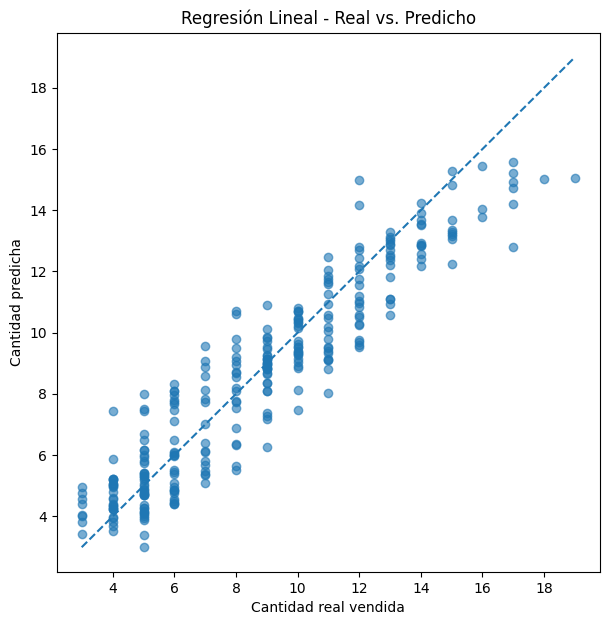

In [ ]:
# ============================================
# 21. REAL VS. PREDICHO
# ============================================

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    pred_final_test,
    alpha=0.6
)

min_val = min(
    y_test.min(),
    pred_final_test.min()
)

max_val = max(
    y_test.max(),
    pred_final_test.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Cantidad real vendida")
plt.ylabel("Cantidad predicha")
plt.title("Regresión Lineal - Real vs. Predicho")

plt.show()

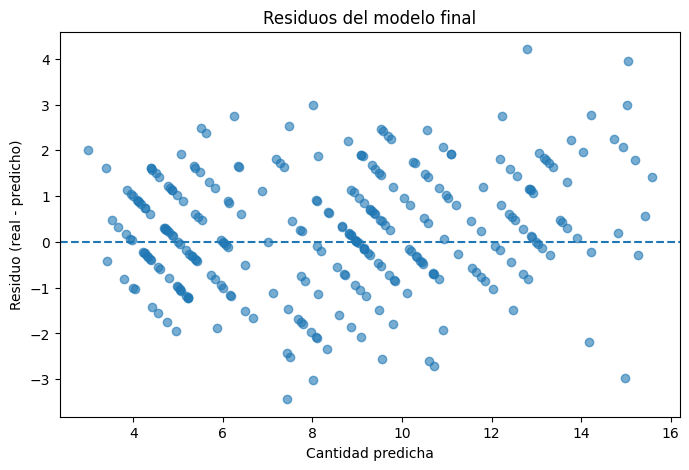

Promedio de residuos: 0.23
Desviación de residuos: 1.2941


In [ ]:
# ============================================
# 22. ANÁLISIS DE RESIDUOS
# ============================================

residuos = y_test - pred_final_test

plt.figure(figsize=(8, 5))

plt.scatter(
    pred_final_test,
    residuos,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Cantidad predicha")
plt.ylabel("Residuo (real - predicho)")
plt.title("Residuos del modelo final")

plt.show()

print("Promedio de residuos:", round(residuos.mean(), 4))
print("Desviación de residuos:", round(residuos.std(), 4))

In [ ]:
# ============================================
# 23. IMPORTANCIA DE VARIABLES
#     MEDIANTE PERMUTATION IMPORTANCE
# ============================================

from sklearn.inspection import permutation_importance

importancia = permutation_importance(
    modelo_final,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="r2"
)

resultado_importancia = pd.DataFrame({
    "Variable": X_test.columns,
    "Importancia_media": importancia.importances_mean,
    "Desviacion": importancia.importances_std
})

resultado_importancia = (
    resultado_importancia
    .sort_values(
        by="Importancia_media",
        ascending=False
    )
)

print(resultado_importancia.round(4))

            Variable  Importancia_media  Desviacion
3              lag_4             0.2449      0.0263
5   promedio_movil_8             0.1918      0.0195
7      descuento_pct             0.0976      0.0122
1              lag_2             0.0890      0.0121
10         categoria             0.0736      0.0109
6        tendencia_4             0.0648      0.0102
8                mes             0.0213      0.0041
9     semana_del_ano             0.0148      0.0033
0              lag_1             0.0138      0.0037
2              lag_3             0.0009      0.0030
4   promedio_movil_4             0.0001      0.0035


In [ ]:
# ============================================
# 24. PRUEBA DE REDUCCIÓN DE CARACTERÍSTICAS
# ============================================

variables_numericas_reducidas = [
    "lag_1",
    "lag_2",
    "lag_4",
    "promedio_movil_8",
    "tendencia_4",
    "descuento_pct",
    "mes",
    "semana_del_ano"
]

caracteristicas_reducidas = (
    variables_numericas_reducidas +
    variables_categoricas
)

preprocesador_reducido = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            "passthrough",
            variables_numericas_reducidas
        )
    ]
)

modelo_lineal_reducido = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador_reducido),
        ("modelo", LinearRegression())
    ]
)

X_train_reducido = train[caracteristicas_reducidas]
X_val_reducido = val[caracteristicas_reducidas]

modelo_lineal_reducido.fit(
    X_train_reducido,
    y_train
)

pred_reducido_val = modelo_lineal_reducido.predict(
    X_val_reducido
)

mae_reducido = mean_absolute_error(
    y_val,
    pred_reducido_val
)

rmse_reducido = root_mean_squared_error(
    y_val,
    pred_reducido_val
)

r2_reducido = r2_score(
    y_val,
    pred_reducido_val
)

print("MODELO COMPLETO")
print("MAE:", round(mae_lineal_val, 4))
print("RMSE:", round(rmse_lineal_val, 4))
print("R²:", round(r2_lineal_val, 4))

print("\nMODELO REDUCIDO")
print("MAE:", round(mae_reducido, 4))
print("RMSE:", round(rmse_reducido, 4))
print("R²:", round(r2_reducido, 4))

MODELO COMPLETO
MAE: 0.9455
RMSE: 1.204
R²: 0.842

MODELO REDUCIDO
MAE: 0.9528
RMSE: 1.2121
R²: 0.8399


In [ ]:
# ============================================
# 25. CLASIFICACIÓN OPERATIVA DE RIESGO
# ============================================

def clasificar_riesgo(stock_actual, stock_minimo, demanda_predicha):
    if stock_actual < demanda_predicha:
        return "ALTO"

    stock_restante = stock_actual - demanda_predicha

    if stock_restante <= stock_minimo:
        return "MEDIO"

    return "BAJO"

In [ ]:
resultado_riesgo = test[
    [
        "nombre",
        "semana",
        "stockActual",
        "stockMinimo"
    ]
].copy()

resultado_riesgo["demanda_predicha"] = pred_final_test

resultado_riesgo["riesgo"] = resultado_riesgo.apply(
    lambda fila: clasificar_riesgo(
        fila["stockActual"],
        fila["stockMinimo"],
        fila["demanda_predicha"]
    ),
    axis=1
)

resultado_riesgo["demanda_predicha"] = (
    resultado_riesgo["demanda_predicha"].round(2)
)

print(resultado_riesgo.head(20))

               nombre     semana  stockActual  stockMinimo  demanda_predicha  \
1584     Gaseosa 1.5L 2026-06-29           14            8              8.98   
1585       Agua 600ml 2026-06-29           13            8              9.37   
1586  Jugo naranja 1L 2026-06-29           17            7             12.90   
1587    Cerveza 330ml 2026-06-29           17            8             10.11   
1588      Malta 400ml 2026-06-29            9            8              8.54   
1589    Té frío 500ml 2026-06-29           18           10             12.52   
1590  Leche entera 1L 2026-06-29           13            8              9.76   
1591           Yogurt 2026-06-29            9            7              7.46   
1592            Queso 2026-06-29           12            6              9.28   
1593            Kumis 2026-06-29           10            7              8.09   
1594      Mantequilla 2026-06-29           11            6             10.70   
1595       Pan tajado 2026-06-29        

In [ ]:
print(
    resultado_riesgo["riesgo"].value_counts()
)

riesgo
MEDIO    219
ALTO      44
BAJO      25
Name: count, dtype: int64


In [ ]:
# ============================================
# 26. RECOMENDACIÓN DE REPOSICIÓN
# ============================================

resultado_riesgo["reposicion_sugerida"] = (
    resultado_riesgo["demanda_predicha"]
    + resultado_riesgo["stockMinimo"]
    - resultado_riesgo["stockActual"]
)

resultado_riesgo["reposicion_sugerida"] = (
    resultado_riesgo["reposicion_sugerida"]
    .clip(lower=0)
    .round()
    .astype(int)
)

print(
    resultado_riesgo[
        [
            "nombre",
            "stockActual",
            "stockMinimo",
            "demanda_predicha",
            "riesgo",
            "reposicion_sugerida"
        ]
    ].head(20)
)

               nombre  stockActual  stockMinimo  demanda_predicha riesgo  \
1584     Gaseosa 1.5L           14            8              8.98  MEDIO   
1585       Agua 600ml           13            8              9.37  MEDIO   
1586  Jugo naranja 1L           17            7             12.90  MEDIO   
1587    Cerveza 330ml           17            8             10.11  MEDIO   
1588      Malta 400ml            9            8              8.54  MEDIO   
1589    Té frío 500ml           18           10             12.52  MEDIO   
1590  Leche entera 1L           13            8              9.76  MEDIO   
1591           Yogurt            9            7              7.46  MEDIO   
1592            Queso           12            6              9.28  MEDIO   
1593            Kumis           10            7              8.09  MEDIO   
1594      Mantequilla           11            6             10.70  MEDIO   
1595       Pan tajado           18           10             13.30  MEDIO   
1596   Pan f

In [ ]:
print(
    resultado_riesgo[
        resultado_riesgo["reposicion_sugerida"] > 0
    ][
        [
            "nombre",
            "riesgo",
            "reposicion_sugerida"
        ]
    ]
    .sort_values(
        by=["riesgo", "reposicion_sugerida"],
        ascending=[True, False]
    )
    .head(20)
)

               nombre riesgo  reposicion_sugerida
1814  Ponqué vainilla   ALTO                   13
1688     Crema dental   ALTO                   10
1697    Té frío 500ml   ALTO                   10
1710      Chocolatina   ALTO                   10
1817             Maní   ALTO                    9
1836     Gaseosa 1.5L   ALTO                    9
1638      Chocolatina   ALTO                    8
1721            Salsa   ALTO                    8
1611             Maíz   ALTO                    7
1616     Crema dental   ALTO                    7
1653      Desodorante   ALTO                    7
1664            Queso   ALTO                    7
1673             Maní   ALTO                    7
1725      Desodorante   ALTO                    7
1747         Galletas   ALTO                    7
1762   Jabón corporal   ALTO                    7
1822      Jabón barra   ALTO                    7
1831          Shampoo   ALTO                    7
1835  Papel higiénico   ALTO                    7


In [ ]:
# ============================================
# 27. GUARDAR EL MODELO FINAL
# ============================================

import joblib

joblib.dump(
    modelo_final,
    "modelo_alertastock_regresion.pkl"
)

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


In [ ]:
# ============================================
# 28. FUNCIÓN FINAL DE PREDICCIÓN
# ============================================

def analizar_producto(datos_producto):

    datos = pd.DataFrame(
        [datos_producto]
    )

    demanda_predicha = float(
        modelo_final.predict(datos)[0]
    )

    stock_actual = datos_producto["stockActual"]
    stock_minimo = datos_producto["stockMinimo"]

    riesgo = clasificar_riesgo(
        stock_actual,
        stock_minimo,
        demanda_predicha
    )

    reposicion = (
        demanda_predicha
        + stock_minimo
        - stock_actual
    )

    reposicion = max(
        0,
        round(reposicion)
    )

    return {
        "demanda_predicha": round(
            demanda_predicha,
            2
        ),
        "riesgo": riesgo,
        "reposicion_sugerida": reposicion
    }

In [ ]:
producto_ejemplo = {
    "lag_1": 10,
    "lag_2": 9,
    "lag_3": 11,
    "lag_4": 10,
    "promedio_movil_4": 10,
    "promedio_movil_8": 9.5,
    "tendencia_4": 0.3,
    "descuento_pct": 5,
    "mes": 8,
    "semana_del_ano": 34,
    "categoria": "Bebidas",

    # Estas dos no entran al modelo,
    # pero se usan para calcular riesgo
    "stockActual": 8,
    "stockMinimo": 6
}

resultado = analizar_producto(
    producto_ejemplo
)

print(resultado)

{'demanda_predicha': 10.69, 'riesgo': 'ALTO', 'reposicion_sugerida': 9}


In [ ]:
{
  "lag_1": 10,
  "lag_2": 9,
  "lag_3": 11,
  "lag_4": 10,
  "promedio_movil_4": 10,
  "promedio_movil_8": 9.5,
  "tendencia_4": 0.3,
  "descuento_pct": 5,
  "mes": 8,
  "semana_del_ano": 34,
  "categoria": "Bebidas",
  "stockActual": 8,
  "stockMinimo": 6
}

{'lag_1': 10,
 'lag_2': 9,
 'lag_3': 11,
 'lag_4': 10,
 'promedio_movil_4': 10,
 'promedio_movil_8': 9.5,
 'tendencia_4': 0.3,
 'descuento_pct': 5,
 'mes': 8,
 'semana_del_ano': 34,
 'categoria': 'Bebidas',
 'stockActual': 8,
 'stockMinimo': 6}

In [ ]:
{
  "demanda_predicha": 10.69,
  "riesgo": "ALTO",
  "reposicion_sugerida": 9
}

{'demanda_predicha': 10.69, 'riesgo': 'ALTO', 'reposicion_sugerida': 9}